# Lesson 13 - Six classes, sound features you can explain, and two classical models

Lessons 03-12 grew into many models and many variants. This lesson starts again from a smaller, cleaner question:

**Which of six classes (background, cargo, fishing, pleasure craft, tanker, tug) does a 5-second clip come
from, on ships never heard in training?**

We use only two classical models, **logistic regression** and **gradient boosting**, and compare two sets of
input numbers:

- **simple:** the average and spread of each mel band (lesson 03), with no MFCCs;
- **engineered:** about 120 numbers computed from the raw audio, each with a physical meaning (tonal lines from
  engines, propeller beat rate, spectral slope, ...).

| Section | Question |
|---|---|
| 1. Which classes | why these six, and why not passenger ships |
| 2. Hours or ships? | every class has 5 h, but not the same number of ships: how training handles it |
| 3. New folds | test sets with the same share of every class |
| 4. The two feature sets | what each number measures, shown on real clips |
| 5. How many MFCCs? | do the higher coefficients help? |
| 6. Results | both models, both feature sets, 5 folds |
| 7. Which features matter | each group alone, and what happens when a group is shuffled |
| 8. What it means | |

The heavy work runs outside the notebook (about an hour on the CPU):
```
python src/six_classes.py features     # raw audio -> data/features6_*.parquet
python src/six_classes.py run          # 5 folds -> runs/six_classes/
```
This notebook explains the method and reads those results. Sections 4 and 7 read a few clips from the audio zip.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import welch
from sklearn.feature_selection import f_classif
from sklearn.metrics import confusion_matrix
import six_classes as S
from features import decode_wav, fix_length
from paths import AUDIO_ZIP, DATA_DIR, RUNS_DIR
from shipzip import SplitZip

OUT = RUNS_DIR / "six_classes"
table, simple, eng = S.load_features(DATA_DIR)
summary = json.loads((OUT / "results.json").read_text())
results = pd.DataFrame(summary["results"])
COLORS = dict(zip(S.CLASSES6, ["#7f7f7f", "#2a78d6", "#1baf7a", "#eb6834", "#9b59b6", "#c0392b"]))
pd.set_option("display.width", 160)

## 1. Which classes

The UniqueShip subset gives every class **the same 5 hours** of audio (about 3,600 clips). What differs is how
many different ships those hours come from:

In [2]:
table["ship"] = S.ship_key(table)
per_class = table.groupby("label").agg(ships=("ship", "nunique"), clips=("ship", "size"),
                                       hours=("duration_sec", lambda s: s.sum() / 3600))
per_class["clips per ship"] = (per_class.clips / per_class.ships).round(1)
per_class["kept"] = ["yes" if c in S.CLASSES6 else "" for c in per_class.index]
print(per_class.sort_values("ships", ascending=False).round(2))
print("\n(background: 'ships' are recording days)")

               ships  clips  hours  clips per ship kept
label                                                  
cargo           2522   3601    5.0             1.4  yes
background       802   3600    5.0             4.5  yes
pleasurecraft    406   3600    5.0             8.9  yes
tug              297   3601    5.0            12.1  yes
fishing          238   3601    5.0            15.1  yes
tanker           233   3601    5.0            15.5  yes
sailing          212   3601    5.0            17.0     
other            169   3601    5.0            21.3     
passengership    110   3600    5.0            32.7     
rescue            23   3600    5.0           156.5     
dredger            6   3601    5.0           600.2     
pilotvessel        2   3601    5.0          1800.5     

(background: 'ships' are recording days)


Earlier lessons showed that **the number of different ships** is what limits recognising new ships: the models
learn individual ships, not ship types (lesson 07, experiment log 3.7). The dataset's own paper finds the same:
doubling the number of ships adds 2.4-2.6 points, doubling the hours of the same ships only 0.8-1.3.

- **Kept:** background, cargo, fishing, pleasure craft, tanker, tug. Each has at least 233 ships (days for
  background).
- **Dropped:** passenger ship (110 ships, the weakest class in the 5-class runs), and the classes earlier lessons
  already found too thin or too mixed: pilot vessel (2 ships), dredger (6), rescue (23), "other" (no common
  sound), and sailing (212 ships, but small craft like pleasure craft).
- **Not downloaded:** the 64 GB "5 Class - Balanced" set. It has the **same ships** as ours (the full dataset has
  110 passenger ships, and we have all 110), only more hours of each, and no fishing or pleasure craft.

## 2. Hours or ships? Weights instead of deleting

Two ways to "balance" a class: the same **hours**, or the same **number of ships**. Hours are already equal.
Ships can't be made equal without throwing data away: cutting cargo to 233 ships would leave about 330 of its
3,600 clips.

So no clip is deleted. Instead, each training clip gets a **weight**:

$$w_{\text{clip}} = \frac{1}{\text{clips of its ship} \times \text{ships in its class}}$$

(then scaled to an average of 1). Every class then has the same total weight, and inside a class every ship has
the same total weight: a tanker's 15 clips together count as much as a cargo ship's single clip. The models see
the weights in training (`sample_weight`), and the same rule weights the validation ships used for choosing
settings.

In [3]:
six = table[table.label.isin(S.CLASSES6)]
w = S.ship_weights(six.label, six.ship)
weights = (pd.DataFrame({"label": six.label.to_numpy(), "ship": six.ship.to_numpy(), "w": w})
           .groupby("label").agg(clips=("w", "size"), ships=("ship", "nunique"), weight_one_clip=("w", "mean"),
                                 class_total=("w", "sum")))
weights["weight_one_ship"] = weights.class_total / weights.ships
print(weights.round(3))

               clips  ships  weight_one_clip  class_total  weight_one_ship
label                                                                     
background      3600    802              1.0     3600.667            4.490
cargo           3601   2522              1.0     3600.667            1.428
fishing         3601    238              1.0     3600.667           15.129
pleasurecraft   3600    406              1.0     3600.667            8.869
tanker          3601    233              1.0     3600.667           15.454
tug             3601    297              1.0     3600.667           12.123


Every class gets the same total (about 3,600). Inside each class the clips per ship hardly vary (every cargo
ship has 1-2 clips, every tanker 15-16), so here the per-ship part changes little compared with plain class
weights. It matters if the data are ever extended unevenly, for example with more clips of a few ships.

## 3. New folds: the same share of every class in every test set

The official folds were split by duration over all 12 classes, so for our six classes the number of test ships
varies a lot from fold to fold. We make five new folds with `StratifiedGroupKFold`:

- **grouped:** all clips of a ship (or a background day) stay in one fold, so no test ship is ever heard in
  training;
- **stratified:** every fold gets about a fifth of every class.

For each run, one fold is the **test** set, the next one the **validation** set (for choosing settings), and
the other three are **training**. After the settings are chosen, the model is trained again on training +
validation, then scored once on the test fold. Every ship is tested exactly once over the five runs.

In [4]:
folds = pd.read_parquet(OUT / "folds.parquet").set_index("row").fold
six = six.assign(fold=folds.reindex(six.index).to_numpy())
new = six.groupby(["label", "fold"]).ship.nunique().unstack()
official = pd.concat({k: six[six[f"split_f{k}"] == "test"].groupby("label").ship.nunique() for k in range(1, 6)},
                     axis=1)
print("test ships per fold, NEW folds:"); print(new)
print("\ntest ships per fold, OFFICIAL folds (same six classes):"); print(official)
print("\nsmallest / largest fold, new:", dict(zip(new.index, zip(new.min(axis=1), new.max(axis=1)))))
print("smallest / largest fold, official:", dict(zip(official.index, zip(official.min(axis=1), official.max(axis=1)))))

test ships per fold, NEW folds:
fold             1    2    3    4    5
label                                 
background     160  161  161  160  160
cargo          505  504  504  505  504
fishing         47   48   48   47   48
pleasurecraft   82   81   81   81   81
tanker          47   46   47   47   46
tug             60   60   59   59   59

test ships per fold, OFFICIAL folds (same six classes):
                 1   2    3    4    5
label                                
background      82  80   81   80   79
cargo          311  87  237  196  286
fishing         31   9   20   14   22
pleasurecraft   50  13   39   21   48
tanker          34  10   20   19   28
tug             39  12   28   26   30

smallest / largest fold, new: {'background': (160, 161), 'cargo': (504, 505), 'fishing': (47, 48), 'pleasurecraft': (81, 82), 'tanker': (46, 47), 'tug': (59, 60)}
smallest / largest fold, official: {'background': (79, 82), 'cargo': (87, 311), 'fishing': (9, 31), 'pleasurecraft': (13, 50), 'tan

## 4. The two feature sets

### 4.1 Simple: 257 numbers, no MFCCs

The log-mel spectrogram (128 bands from 10 Hz to 16 kHz, lesson 02), summarised over the 5 seconds: the
**average** and the **spread** of each band, plus the overall average. This is lesson 03's baseline, and it is
the "normal model" here.

### 4.2 Engineered: seven groups with a physical meaning

Computed from the raw 32 kHz audio (`engineered_features` in `src/six_classes.py`). The idea follows the
interpretable features of the marine-mammal assignment (summaries over time, so it doesn't matter *when* in the
clip a sound occurs), extended with features that sonar operators use for ships:

| Group | What it measures | Why it could tell ships apart | Numbers |
|---|---|---|---|
| MFCC | shape of the spectrum (DCT of 40 log-mel energies): mean, spread, how fast it changes | overall timbre | 3 per coefficient kept |
| 1/3-octave levels | level in each standard 1/3-octave band, 20 Hz - 12.5 kHz (the bands used to measure ship noise) | big ships are loud at low frequencies, small fast boats higher up | 29 |
| level changes over time | how much each octave band's level varies during the clip | steady machinery hum against fluctuating noise | 9 |
| spectral shape | per frame: centroid, bandwidth, 85 % roll-off, flatness, flux, energy, zero-crossing rate; each as mean, std, 10th and 90th percentile | where the energy sits, tonal or noise-like | 28 |
| loudness and impulsiveness | broadband level, spectral slope (dB per decade), low minus high level, kurtosis, crest factor | slope and balance of low and high frequencies; clicks and knocks | 5 |
| tonal lines (LOFAR) | narrow peaks at least 6 dB above the surrounding spectrum, 10-1,000 Hz: how many, strongest frequency and height, share of power | engines and generators produce steady tones | 5 |
| propeller modulation (DEMON) | the 2-10 kHz noise's loudness beats at the propeller's shaft and blade rates: depth of the beat, its spectrum in 8 bands from 1 to 150 Hz, peak rate and peak height | slow big propellers against fast small ones | 11 |

The equations, for one clip $x(n)$ with power spectrogram $P(f,t)$ (64 ms frames, 16 ms apart) and long-term
spectrum $L(f)$ (Welch average of 0.5 s segments, 2 Hz apart):

| Feature | Equation |
|---|---|
| 1/3-octave level, band centre $f_c$ | $L_{f_c} = 10\log_{10} \sum_{f_c 2^{-1/6} \le f < f_c 2^{1/6}} L(f)\,\Delta f$ |
| spectral centroid | $C(t) = \sum_f f\,p(f,t)$ with $p(f,t) = P(f,t)/\sum_f P(f,t)$ |
| flatness | $\Phi(t) = \exp\left(\overline{\ln P(f,t)}\right) / \overline{P(f,t)}$ (1 for noise, near 0 for a pure tone) |
| flux | $\sqrt{\sum_f \left(p(f,t)-p(f,t-1)\right)^2}$ |
| spectral slope | straight-line fit of the 1/3-octave levels per Hz against $\log_{10} f$, 50 Hz - 10 kHz |
| kurtosis | $\overline{(x-\bar x)^4}/\sigma^4 - 3$ (0 for Gaussian noise, large for clicks) |
| tonal height | $10\log_{10} L(f) - \text{median}_{\pm 50\,\text{Hz}}\, 10\log_{10} L(f)$ |
| DEMON envelope | $e(m) = \sqrt{\text{mean}_{\text{2.5 ms}}\, x_{2-10\,\text{kHz}}^2}$, then $\lvert \text{FFT}\{e\}\rvert^2$ |

Below, one clip per class (the clip recorded closest to the hydrophone, where the ship is clearest), with the
detected tonal lines and the DEMON peak marked.

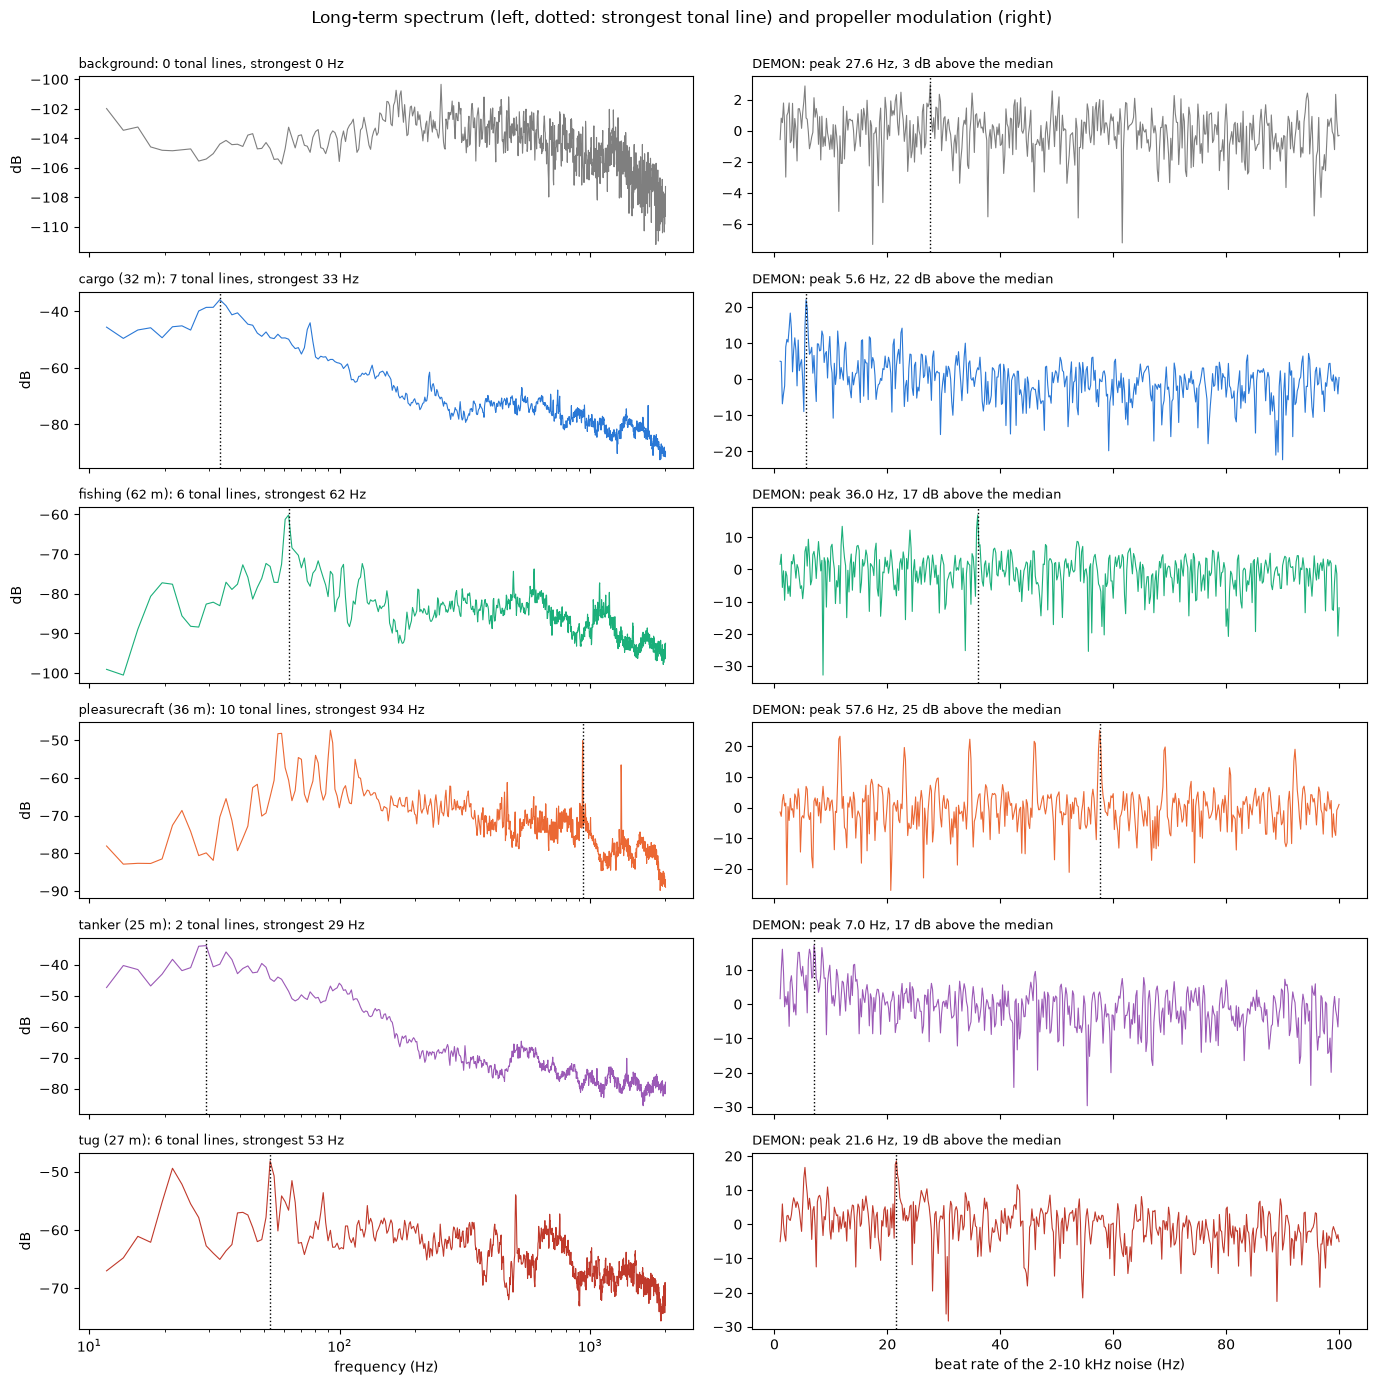

In [5]:
zf = SplitZip(str(AUDIO_ZIP))
ships_only = six[six.label != "background"]
examples = {c: ships_only[ships_only.label == c].mean_distance.idxmin() for c in S.CLASSES6 if c != "background"}
examples = {"background": six[six.label == "background"].index[0]} | examples
waves = {c: fix_length(decode_wav(zf.read(table.zip_name[r]))[0]) for c, r in examples.items()}

fig, axes = plt.subplots(len(waves), 2, figsize=(14, 2.3 * len(waves)), sharex="col")
for i, (c, x) in enumerate(waves.items()):
    f = S.engineered_features(x)
    fw, psd = welch(x - x.mean(), S.SR, nperseg=S.WELCH_SEG, noverlap=S.WELCH_SEG // 2)
    sel = (fw >= 10) & (fw <= 2000)
    axes[i, 0].semilogx(fw[sel], 10 * np.log10(psd[sel] + 1e-30), color=COLORS[c], lw=0.8)
    if f["tonal_count"]:
        axes[i, 0].axvline(f["tonal_strongest_hz"], color="k", ls=":", lw=1)
    axes[i, 0].set_ylabel("dB")
    d = table.mean_distance[examples[c]]
    axes[i, 0].set_title(f"{c}{'' if np.isnan(d) else f' ({d:.0f} m)'}: {f['tonal_count']:.0f} tonal lines, "
                         f"strongest {f['tonal_strongest_hz']:.0f} Hz", fontsize=9, loc="left")
    env = np.sqrt((S.sosfilt(S.DEMON_SOS, x - x.mean()) ** 2).reshape(-1, S.SR // S.DEMON_RATE).mean(1))
    M = np.abs(np.fft.rfft(S.detrend(env) * np.hanning(len(env)))) ** 2
    fm = np.fft.rfftfreq(len(env), 1 / S.DEMON_RATE)
    keep = (fm >= 1) & (fm <= 100)
    axes[i, 1].plot(fm[keep], 10 * np.log10(M[keep] / np.median(M[keep])), color=COLORS[c], lw=0.8)
    axes[i, 1].axvline(f["demon_peak_hz"], color="k", ls=":", lw=1)
    axes[i, 1].set_title(f"DEMON: peak {f['demon_peak_hz']:.1f} Hz, {f['demon_peak_db']:.0f} dB above the median",
                         fontsize=9, loc="left")
axes[-1, 0].set_xlabel("frequency (Hz)"); axes[-1, 1].set_xlabel("beat rate of the 2-10 kHz noise (Hz)")
fig.suptitle("Long-term spectrum (left, dotted: strongest tonal line) and propeller modulation (right)", y=1.0)
plt.tight_layout(); plt.show()

## 5. How many MFCCs?

MFCC $k$ describes ever finer ripples of the spectrum's shape as $k$ grows. For ship noise the higher ones might
carry little but noise. We store MFCCs 1-19 and let the data decide: the MFCC group **alone** is trained with
the first 4, 8, 12, 16 or 19 coefficients and scored on the **validation** ships (never the test ships). The
engineered set keeps the smallest number that comes within half a point of the best.

model   gradient boosting  logistic regression  mean
n_mfcc                                              
4                    46.1                 43.0  44.5
8                    48.4                 45.2  46.8
12                   50.1                 46.3  48.2
16                   50.8                 46.6  48.7
19                   51.7                 47.0  49.3

kept: MFCCs 1..19


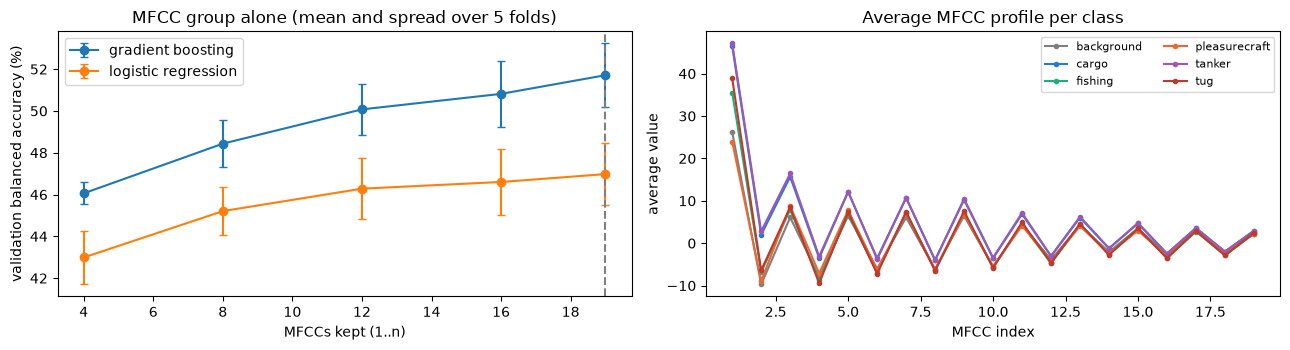

In [6]:
sweep = pd.read_csv(OUT / "mfcc_sweep.csv")
table_sweep = sweep.pivot_table(index="n_mfcc", columns="model", values="val_balanced_accuracy", aggfunc="mean")
table_sweep["mean"] = table_sweep.mean(axis=1)
print((100 * table_sweep).round(1))
print(f"\nkept: MFCCs 1..{summary['n_mfcc']}")

mfcc_means = eng[[f"mfcc_{k}_mean" for k in range(1, S.N_MFCC + 1)]].join(table.label)
profile = mfcc_means.groupby("label").mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for model, g in sweep.groupby("model"):
    m = g.groupby("n_mfcc").val_balanced_accuracy
    ax[0].errorbar(m.mean().index, 100 * m.mean(), yerr=100 * m.std(), marker="o", capsize=3, label=model)
ax[0].axvline(summary["n_mfcc"], color="grey", ls="--")
ax[0].set_xlabel("MFCCs kept (1..n)"); ax[0].set_ylabel("validation balanced accuracy (%)")
ax[0].set_title("MFCC group alone (mean and spread over 5 folds)"); ax[0].legend()
for c, row in profile.iterrows():
    ax[1].plot(range(1, S.N_MFCC + 1), row.to_numpy(), "o-", ms=3, color=COLORS[c], label=c)
ax[1].set_xlabel("MFCC index"); ax[1].set_ylabel("average value"); ax[1].set_title("Average MFCC profile per class")
ax[1].legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

**The higher MFCCs do help here.** Every step from 4 to 19 coefficients raises the validation score, for both
models (gradient boosting 46.1 % -> 51.7 %, logistic regression 43.0 % -> 47.0 %), so the rule keeps all 19.
The higher coefficients have small values (right plot), but small is not the same as useless: after
standardising, a model looks at how they *differ between classes*, and cargo and tanker stay apart from the
others up to MFCC 19. They describe finer detail of the spectrum, such as narrow peaks.

The zigzag in the right plot is the same for every class. A spectrum that falls steadily from low to high
frequencies (as ship noise does) turns into exactly this pattern of large odd and small even coefficients after
the DCT. The class information is in the differences between the lines, not in the zigzag.

## 6. Results: both models, both feature sets, 5 folds

All numbers are on the **test** fold, averaged over the five folds (± is the spread between folds). Random
guessing gives 16.7 %. **Balanced accuracy** (the average of the six per-class accuracies) is the main number;
**per ship** first averages the probabilities over all clips of a ship (or background day), then counts ships.

                                      numbers per clip    accuracy balanced_accuracy    macro_f1 per_ship_balanced_accuracy
features         model                                                                                                     
simple (no MFCC) logistic regression               257  56.9 ± 1.3        56.9 ± 1.3  56.4 ± 1.3                 64.9 ± 2.5
                 gradient boosting                 257  58.4 ± 1.2        58.4 ± 1.1  57.9 ± 1.2                 66.6 ± 2.8
engineered       logistic regression               144  60.8 ± 1.3        60.8 ± 1.3  60.4 ± 1.4                 67.3 ± 1.8
                 gradient boosting                 144  61.9 ± 1.1        61.9 ± 1.1  61.4 ± 1.2                 70.5 ± 2.2

settings chosen on validation (C for logistic regression, number of trees for gradient boosting):
fold                                      1       2       3       4       5
features         model                                                     
engin

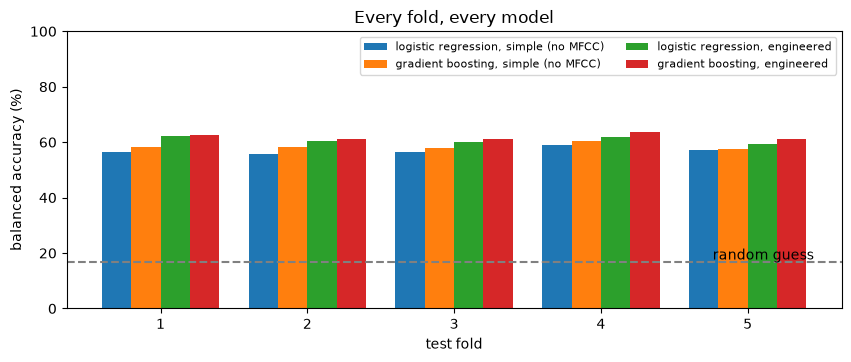

In [7]:
cols = ["accuracy", "balanced_accuracy", "macro_f1", "per_ship_balanced_accuracy"]
main = results.groupby(["features", "model"], sort=False)[cols]
show = (100 * main.mean()).round(1).astype(str) + " ± " + (100 * main.std()).round(1).astype(str)
show.insert(0, "numbers per clip", [summary["feature_sets"][fs] for fs, _ in show.index])
print(show.to_string())
print("\nsettings chosen on validation (C for logistic regression, number of trees for gradient boosting):")
print(results.pivot_table(index=["features", "model"], columns="fold", values="setting", aggfunc="first"))

fig, ax = plt.subplots(figsize=(10, 3.6))
for i, ((fs, model), g) in enumerate(results.groupby(["features", "model"], sort=False)):
    ax.bar(np.arange(1, 6) + (i - 1.5) * 0.2, 100 * g.sort_values("fold").balanced_accuracy, 0.2,
           label=f"{model}, {fs}")
ax.axhline(100 / 6, color="grey", ls="--"); ax.text(5.45, 100 / 6 + 1, "random guess", ha="right")
ax.set_xlabel("test fold"); ax.set_ylabel("balanced accuracy (%)"); ax.set_ylim(0, 100)
ax.legend(fontsize=8, ncol=2); ax.set_title("Every fold, every model"); plt.show()

- **The engineered features win, with fewer numbers:** 144 numbers against 257, and +3.5 points (gradient
  boosting, 58.4 -> 61.9 %) and +3.9 points (logistic regression, 56.9 -> 60.8 %). Gradient boosting with the
  engineered features is better than with the simple ones on every one of the five folds.
- **Gradient boosting is 1-1.5 points ahead of logistic regression** with either feature set: a small gap. The
  classes can be separated mostly by weighted sums of these numbers.
- **One answer per ship is better than one per clip:** 70.5 % of ships (and background days) are classified
  correctly when their clips' probabilities are averaged.
- **The folds agree:** ± 1.1 to 1.3 points between folds, against ± 4.4 (5-class CNN) and ± 9 (12-class
  baseline) with the official folds. The balanced folds make the average trustworthy. Accuracy and balanced
  accuracy are equal here because every test fold has about the same number of clips of each class.
- Logistic regression chose strong regularisation on validation (C = 0.01-0.1, small = strong), and gradient
  boosting stopped at 120-180 trees: both signs that the models would otherwise learn the training ships.

### Which classes get confused

The predictions of all five test folds put together (every clip is tested once), for the best combination.

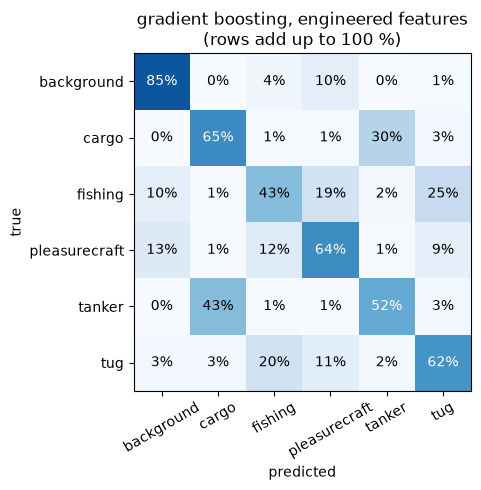

recall per class (share of each class's test clips classified correctly), mean over folds:
                 simple (no MFCC)                            engineered                  
              logistic regression gradient boosting logistic regression gradient boosting
background                   82.2              85.1                83.7              85.3
cargo                        57.0              59.3                59.3              64.7
fishing                      38.9              39.8                43.5              43.3
pleasurecraft                56.9              59.2                61.1              64.1
tanker                       54.9              52.7                57.6              52.3
tug                          51.6              54.6                59.7              61.7


In [8]:
preds = pd.read_parquet(OUT / "predictions.parquet")
best = results.groupby(["features", "model"]).balanced_accuracy.mean().idxmax()
p = preds[(preds.features == best[0]) & (preds.model == best[1])]
probs = p[[f"p_{c}" for c in S.CLASSES6]].to_numpy()
cm = confusion_matrix(p.y, probs.argmax(1), normalize="true")
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
ax.set_xticks(range(6), S.CLASSES6, rotation=30); ax.set_yticks(range(6), S.CLASSES6)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{best[1]}, {best[0]} features\n(rows add up to 100 %)")
plt.tight_layout(); plt.show()

recall = pd.DataFrame({k: pd.DataFrame(list(g.per_class_recall)).mean() for k, g in
                       results.groupby(["features", "model"], sort=False)})
print("recall per class (share of each class's test clips classified correctly), mean over folds:")
print((100 * recall).round(1))

- **Cargo against tanker is the main confusion:** 30 % of cargo clips are called tanker and 43 % of tanker clips
  cargo. Both are large, slow merchant ships with similar engines and propellers (section 7 shows their spectra
  lying on top of each other). The dataset's paper finds the same confusion.
- **The small and working boats get mixed among themselves:** fishing is taken for tug (25 %) or pleasure craft
  (19 %), tug for fishing (20 %). Fishing is the hardest class (43 %).
- **Background is the easiest (85 %).** Its errors go mostly to pleasure craft: a quiet small boat far away
  sounds like no boat.
- **The engineered features help most for tug (+7 points), cargo (+5), pleasure craft (+5) and fishing (+3.5)**
  (gradient boosting); tanker and background stay where they were.

### Distance and hydrophone: could the levels be a shortcut?

Many engineered numbers are levels. A level could separate the classes for the wrong reason: if one class were
mostly recorded closer to the hydrophone, or mostly by the other hydrophone. Below: the share of each ship class
per hydrophone, the median distance, and the balanced accuracy of the best combination by distance (ship classes
only, so chance is 20 %; a clip wrongly called background counts as wrong).

In [9]:
ship_table = six[six.label != "background"]
print(pd.crosstab(ship_table.label, ship_table.hydrophone, normalize="index").round(2).join(
    ship_table.groupby("label").mean_distance.median().round(0).rename("median distance (m)")))

dist = table.mean_distance.reindex(p.row).to_numpy()
y_test = p.y.to_numpy()
ship_rows = y_test != S.CLASSES6.index("background")
by_dist = pd.DataFrame({"y": y_test[ship_rows], "right": (probs.argmax(1) == y_test)[ship_rows],
                        "band": pd.cut(dist[ship_rows], [0, 700, 1400, np.inf],
                                       labels=["< 700 m", "700-1,400 m", "> 1,400 m"])})
print(by_dist.groupby("band", observed=True).apply(
    lambda g: pd.Series({"clips": len(g), "balanced accuracy %": 100 * g.groupby("y").right.mean().mean()}),
    include_groups=False).round(1))

               ICLISTENAF2523  ICLISTENAF2556  median distance (m)
label                                                             
cargo                    0.79            0.21                994.0
fishing                  0.82            0.18               1486.0
pleasurecraft            0.80            0.20               1353.0
tanker                   0.79            0.21                867.0
tug                      0.79            0.21               1359.0
              clips  balanced accuracy %
band                                    
< 700 m      4176.0                 61.0
700-1,400 m  6771.0                 60.5
> 1,400 m    7016.0                 51.8


- **Hydrophone: no shortcut.** Every ship class is recorded about 80 % by hydrophone 2523 and 20 % by 2556.
- **Distance: a small one.** Cargo ships and tankers pass closer (median about 900 m) than fishing boats, pleasure
  craft and tugs (about 1,350-1,500 m), probably because they use the shipping lane. Sound spreading over
  1.5 times the distance loses about $20\log_{10} 1.5 \approx 4$ dB, while the big ships are 20-30 dB louder at
  50 Hz (section 7). So the level differences come mostly from the ships themselves, but a few dB of them is
  distance.
- **Far ships are harder:** about 61 % within 1,400 m, 52 % beyond, as in every earlier lesson.

## 7. Which features matter

Two views of the engineered groups:

- **alone:** each group is the only input, trained and tested like the full set;
- **shuffled:** in the full model, one group's values are shuffled between test clips (all its columns
  together), and we measure how much balanced accuracy drops. A big drop means the model relies on that group.
  Groups that carry the same information can stand in for each other, so a small drop doesn't always mean a
  group is useless.

                              numbers  alone: LR  alone: GB  shuffled drop: LR  shuffled drop: GB
group                                                                                            
1/3-octave levels                  29       54.2       54.5               28.8               24.4
spectral shape                     28       51.6       53.8                9.7                5.2
MFCC                               57       47.2       52.4               10.7                7.2
loudness and impulsiveness          5       49.2       49.3                2.7                2.0
propeller modulation (DEMON)       11       36.9       40.8                4.6                3.8
tonal lines                         5       34.0       39.1                1.9                1.5
level changes over time             9       30.8       37.7                2.8                2.7


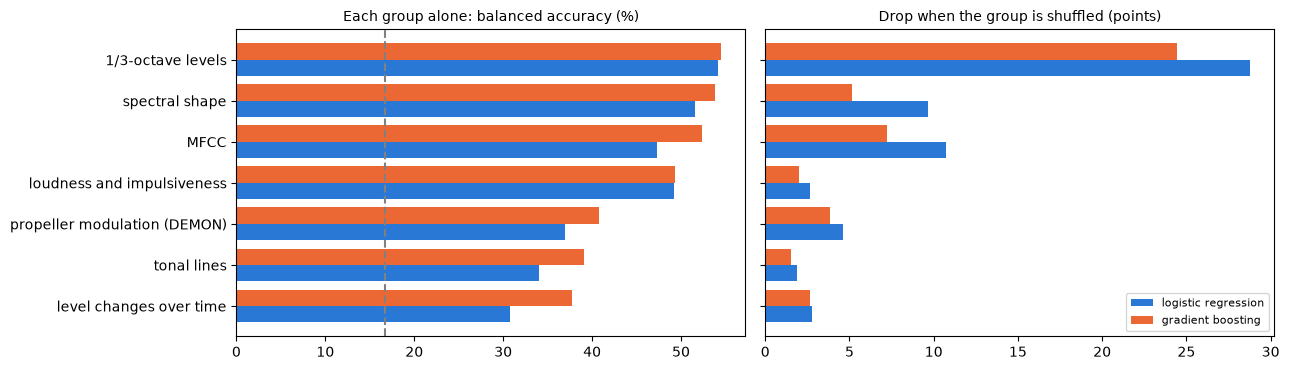

In [10]:
alone = pd.read_csv(OUT / "group_alone.csv")
imp = pd.read_csv(OUT / "group_importance.csv")
view = pd.concat({
    "numbers": alone.groupby("group").n_features.first(),
    "alone: LR": 100 * alone[alone.model == "logistic regression"].groupby("group").balanced_accuracy.mean(),
    "alone: GB": 100 * alone[alone.model == "gradient boosting"].groupby("group").balanced_accuracy.mean(),
    "shuffled drop: LR": 100 * imp[imp.model == "logistic regression"].groupby("group").drop.mean(),
    "shuffled drop: GB": 100 * imp[imp.model == "gradient boosting"].groupby("group").drop.mean()}, axis=1)
print(view.sort_values("alone: GB", ascending=False).round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
order = view.sort_values("alone: GB").index
for j, (key, title) in enumerate([("alone", "Each group alone: balanced accuracy (%)"),
                                  ("shuffled drop", "Drop when the group is shuffled (points)")]):
    y = np.arange(len(order))
    ax[j].barh(y - 0.2, view.loc[order, f"{key}: LR"], 0.4, label="logistic regression", color="#2a78d6")
    ax[j].barh(y + 0.2, view.loc[order, f"{key}: GB"], 0.4, label="gradient boosting", color="#eb6834")
    ax[j].set_yticks(y, order if j == 0 else [""] * len(order)); ax[j].set_title(title, fontsize=10)
ax[0].axvline(100 / 6, color="grey", ls="--")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

- **The 1/3-octave levels carry the most:** alone they reach 54.5 %, close to the 257 simple numbers (58.4 %),
  with 29 numbers; shuffling them costs the full model 24-29 points. Which frequency bands are loud is the main
  clue.
- **Spectral shape and MFCC come next** (52-54 % alone, gradient boosting), and each still costs 5-11 points
  when shuffled, so they add information the levels don't have.
- **Five numbers of loudness and impulsiveness reach 49 % on their own** (spectral slope, low minus high level,
  kurtosis, crest factor, broadband level).
- **The ship-specific groups are weaker alone but not useless:** tonal lines 39 %, propeller modulation (DEMON)
  41 %, level changes over time 38 %, all far above the 16.7 % of random guessing. Most of what they know is also
  in the spectrum, so shuffling them costs only 1.5-4.6 points. DEMON costs the most of the three: the propeller
  rate is information the spectrum alone doesn't give.

### What the classes sound like, in these numbers

The eight engineered numbers that differ most between the classes (largest F-statistic: variation between the
class averages compared with the variation inside the classes), one box per class. This describes the data; it
was not used to choose any model.

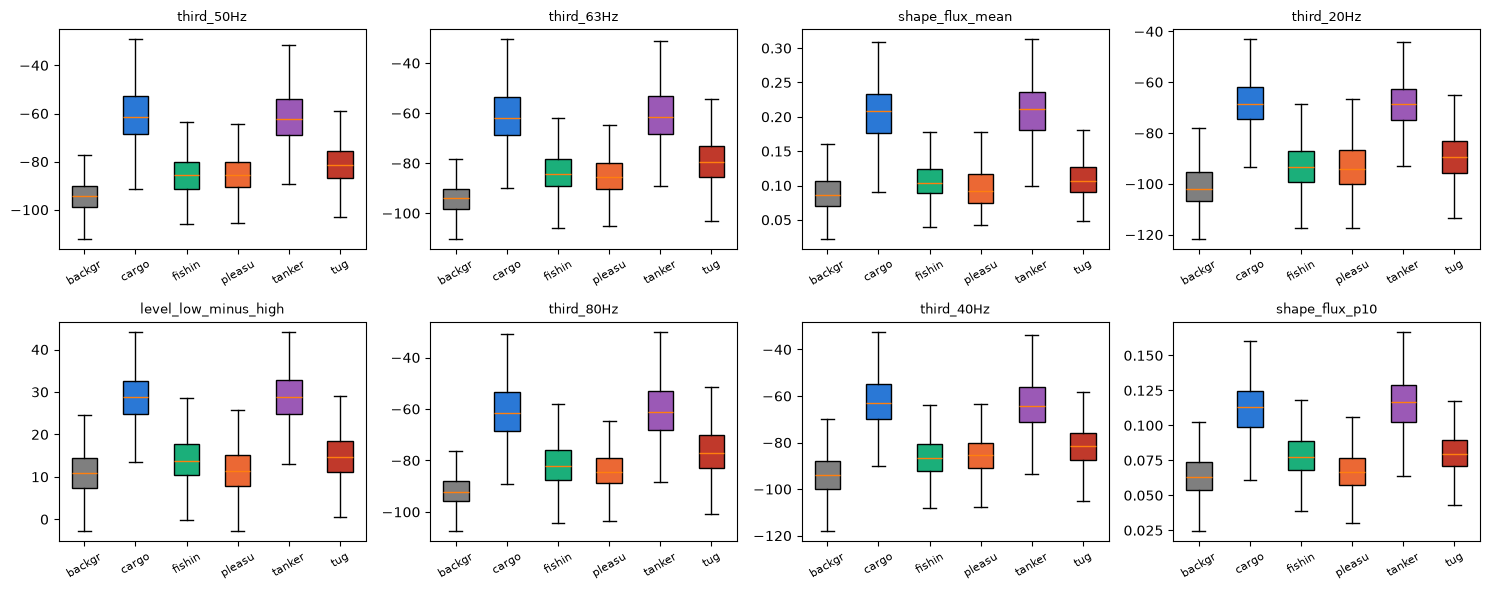

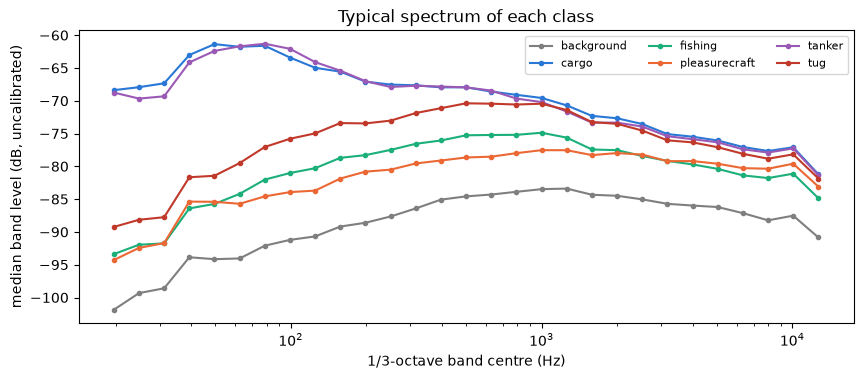

In [11]:
eng6 = eng.join(table.label)
F, _ = f_classif(eng6.drop(columns="label").fillna(0), eng6.label)
top = pd.Series(F, index=eng6.columns[:-1]).sort_values(ascending=False).head(8).index
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, name in zip(axes.ravel(), top):
    data = [eng6.loc[eng6.label == c, name].to_numpy() for c in S.CLASSES6]
    bp = ax.boxplot(data, showfliers=False, patch_artist=True)
    for patch, c in zip(bp["boxes"], S.CLASSES6):
        patch.set_facecolor(COLORS[c])
    ax.set_xticks(range(1, 7), [c[:6] for c in S.CLASSES6], rotation=30, fontsize=8)
    ax.set_title(name, fontsize=9)
plt.tight_layout(); plt.show()

levels = eng6.groupby("label")[[f"third_{n}Hz" for n in S.THIRD_OCTAVE_NAMES]].median()
fig, ax = plt.subplots(figsize=(10, 3.8))
for c, row in levels.iterrows():
    ax.semilogx(S.THIRD_OCTAVES, row.to_numpy(), "o-", ms=3, color=COLORS[c], label=c)
ax.set_xlabel("1/3-octave band centre (Hz)"); ax.set_ylabel("median band level (dB, uncalibrated)")
ax.set_title("Typical spectrum of each class"); ax.legend(fontsize=8, ncol=3); plt.show()

The two pictures say the same thing in sound: **cargo ships and tankers are 20-30 dB louder below 100 Hz** than
the other boats (big, slow engines and propellers), and their spectrum changes faster from frame to frame
(`shape_flux`). Tugs sit between the big ships and the small boats; fishing boats and pleasure craft are the
quietest at low frequencies. Cargo and tanker lie on top of each other at every frequency, which is why they are
confused.

## 8. What it means

**The six-class problem, on ships never heard in training (5 balanced folds, balanced accuracy, chance 16.7 %):**

| Features | Logistic regression | Gradient boosting | Per ship (GB) |
|---|---|---|---|
| simple: mel band mean + spread, no MFCC (257) | 56.9 ± 1.3 % | 58.4 ± 1.1 % | 66.6 % |
| **engineered: seven interpretable groups (144)** | **60.8 ± 1.3 %** | **61.9 ± 1.1 %** | **70.5 %** |

- **Interpretable features beat plain band statistics** by 3.5-3.9 points with fewer numbers, and they explain
  *why*: big ships are loud below 100 Hz, propellers beat at different rates, small boats are quieter and
  higher-pitched.
- **Above 60 % with two classical models.** For comparison, our 12-class CNN's predictions limited to these six
  classes give about 57 % balanced accuracy (fold 1 of the official folds, so only a rough comparison). A CNN is
  not needed to reach this level.
- **Higher MFCCs help, so they were kept** (section 5).
- **The balanced folds make the result stable** (± 1 point between folds instead of ± 4-9), and the ship weights
  make every class and every ship count the same without deleting a clip.
- **What limits us now is cargo against tanker** (similar ships, 30-43 % confused) and the small boats among
  themselves. Merging cargo and tanker into "large merchant ship" would remove the largest confusion, but it
  changes the question, so it would be a decision for the group.

**Limits of this lesson:**

- One random seed and one choice of folds. The fold spread (± 1 point) shows the result doesn't depend much on
  which ships are tested.
- Levels are not calibrated (the WAV files are not in µPa) and partly depend on distance (section 6).
- The number of MFCCs was chosen on the validation folds of all five runs together. Each validation fold is
  another run's test fold, so this one choice (out of five values) saw a little of the test data. The other
  settings (C, number of trees) were chosen inside each run.
- These results use new folds, so they can't be compared number-for-number with the dataset's paper or with
  our earlier runs on the official folds.